In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
import sys

project_root = Path().cwd().parents[0]
sys.path.insert(0, str(project_root))

from scripts.explanatory_data_analysis import (
    fetch_dataset_and_turn_into_dataframe_and_convert_column_names_to_lowercase,
    dataset_quality_inspection,
)
from scripts.data_preprocessing import (
    data_clues_and_target,
    data_train_test_split,
    identify_feature_groups,
    create_numerical_imputer,
    create_categorical_imputer,
    create_ordinal_encoder,
    create_binary_encoder,
    create_nominal_encoder,
    create_social_media_screen_time_transformer,
    create_numerical_scaler,
    create_numerical_pipeline,
    create_ordinal_pipeline,
    create_nominal_pipeline,
    create_binary_pipeline,
    create_preprocessor,
)

from scripts.model_training import (
    create_model_pipeline,
    evaluate_model_with_cross_validation,
    optimize_model_with_grid_search
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

raw_data_path = project_root / "data" / "raw" / "student_mental_health.csv"

raw_df = fetch_dataset_and_turn_into_dataframe_and_convert_column_names_to_lowercase(
    raw_data_path
)

clues_and_target = data_clues_and_target(raw_df)

# DataFrame Model Clues
X = clues_and_target["X"]
# DataFrame Model Target
y = clues_and_target["y"]


display(X.columns)
display(y)

Index(['age', 'gender', 'year_of_study', 'sleep_hours', 'study_hours_per_week',
       'gpa', 'social_media_hours', 'screen_time_hours', 'physical_activity',
       'financial_stress', 'family_support', 'attendance_rate',
       'part_time_job', 'diet_quality', 'previous_mental_health_history'],
      dtype='str')

0         High
1       Medium
2       Medium
3         High
4       Medium
         ...  
1995    Medium
1996      High
1997      High
1998       Low
1999    Medium
Name: mental_health_risk, Length: 2000, dtype: str

In [2]:
# Data Train Test Split
X_train, X_test, y_train, y_test = data_train_test_split(raw_df)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape[0])
print(y_test.shape[0])

print("=" * 30)

# Make sure the traget distribution is balanced
print("TRAIN TARGET DISTRIBUTION")
print(y_train.value_counts(normalize=True) * 100)
print("=" * 30)
print("TEST TARGET DISTRIBUTION")
print(y_test.value_counts(normalize=True) * 100)

(1600, 15)
(400, 15)
1600
400
TRAIN TARGET DISTRIBUTION
mental_health_risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64
TEST TARGET DISTRIBUTION
mental_health_risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


In [3]:
# Identify data feature groups
feature_groups = identify_feature_groups(X_train)
numerical_group = feature_groups["numerical_group"]
ordinal_categorical_group = feature_groups["ordinal_categorical_group"]
nominal_categorical_group = feature_groups["nominal_categorical_group"]
binary_categorical_group = feature_groups["binary_categorical_group"]

print(f"NUMERICAL GROUP: {numerical_group}")
print("=" * 30)
print(f"ORDINAL CATEGORICAL GROUP: {ordinal_categorical_group}")
print("=" * 30)
print(f"NOMINAL CATEGORICAL GROUP: {nominal_categorical_group}")
print("=" * 30)
print(f"BINARY CATEGOIRICAL GROUP: {binary_categorical_group}")

NUMERICAL GROUP: ['age', 'year_of_study', 'sleep_hours', 'study_hours_per_week', 'gpa', 'social_media_hours', 'screen_time_hours', 'financial_stress', 'family_support', 'attendance_rate']
ORDINAL CATEGORICAL GROUP: ['physical_activity', 'diet_quality']
NOMINAL CATEGORICAL GROUP: ['gender']
BINARY CATEGOIRICAL GROUP: ['part_time_job', 'previous_mental_health_history']


In [4]:
# Initialize numerical pipeline
numerical_pipeline = create_numerical_pipeline(
    imputer=create_numerical_imputer(),
    transformer=create_social_media_screen_time_transformer(),
    scaler=create_numerical_scaler(),
)

# Initialize ordinal pipeline
ordinal_pipeline = create_ordinal_pipeline(
    imputer=create_categorical_imputer(), encoder=create_ordinal_encoder()
)

# Initialize nominal pipeline
nominal_pipeline = create_nominal_pipeline(
    imputer=create_categorical_imputer(), encoder=create_nominal_encoder()
)

# Initialize binary pipeline
binary_pipeline = create_binary_pipeline(
    imputer=create_categorical_imputer(), encoder=create_binary_encoder()
)

# Initialize preprocessor (ColumnTransformer)
preprocessor = create_preprocessor(
    numerical_pipeline=numerical_pipeline,
    ordinal_pipeline=ordinal_pipeline,
    nominal_pipeline=nominal_pipeline,
    binary_pipeline=binary_pipeline,
    numerical_group=numerical_group,
    ordinal_categorical_group=ordinal_categorical_group,
    nominal_categorical_group=nominal_categorical_group,
    binary_categorical_group=binary_categorical_group,
)

In [5]:
## Initialize models pipelines

# Initialize LogisticRegression pipeline 
logistic_regression_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_regression_pipeline = create_model_pipeline(preprocessor=preprocessor, classifier=logistic_regression_model)

# Initialize RandromForestClassifier pipeline
random_forest_classifier_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight=None,
    random_state=42,
    n_jobs=-1
)
random_forest_classifier_pipeline = create_model_pipeline(preprocessor=preprocessor, classifier=random_forest_classifier_model)

# Initialize Support Vector Classifier pipeline
support_vector_model = SVC(
    C=1.0,
    kernel="rbf",
    gamma="scale",
    class_weight=None
)
support_vector_model_pipeline = create_model_pipeline(preprocessor=preprocessor, classifier=support_vector_model)

In [6]:
# Testing models using cross validation

## LOGISTIC REGRESSION
lr_cv_results = evaluate_model_with_cross_validation(
    pipeline=logistic_regression_pipeline, X_train=X_train, y_train=y_train
)
lr_cv_results_df = pd.DataFrame(lr_cv_results)
print("LOGISTIC REGRESSION RESULTS")
display(lr_cv_results_df)

## RANDOM FOREST
rf_cv_results = evaluate_model_with_cross_validation(
    pipeline=random_forest_classifier_pipeline, X_train=X_train, y_train=y_train
)
rf_cv_results_df = pd.DataFrame(rf_cv_results)
print("RANDOM FORREST RESULTS")
display(rf_cv_results_df)

## SUPPORT VECOTR CLASSIFIER
svc_cv_results = evaluate_model_with_cross_validation(
    pipeline=support_vector_model_pipeline, X_train=X_train, y_train=y_train
)
svc_cv_results_df = pd.DataFrame(svc_cv_results)
print("SUPPORT VECTOR CLASSIFIER RESULTS")
display(svc_cv_results_df)

LOGISTIC REGRESSION RESULTS


,fit_time,score_time,test_accuracy,train_accuracy,test_precision_macro,train_precision_macro,test_recall_macro,train_recall_macro,test_f1_macro,train_f1_macro
0,0.154437,0.049618,0.750000,0.759375,0.745571,0.757934,0.749418,0.758794,0.746957,0.758340
1,0.109476,0.050477,0.731250,0.770312,0.737886,0.770327,0.731268,0.769665,0.733819,0.769979
2,0.122098,0.067514,0.734375,0.767969,0.729607,0.769294,0.733633,0.767589,0.731095,0.768329
3,0.101045,0.051593,0.753125,0.764062,0.753688,0.765405,0.751846,0.763609,0.751681,0.764425
4,0.135587,0.064670,0.787500,0.758594,0.793632,0.759485,0.787346,0.758065,0.789301,0.758724


RANDOM FORREST RESULTS


,fit_time,score_time,test_accuracy,train_accuracy,test_precision_macro,train_precision_macro,test_recall_macro,train_recall_macro,test_f1_macro,train_f1_macro
0,0.915556,0.210195,0.709375,0.993750,0.701116,0.993735,0.708362,0.993706,0.702216,0.993718
1,0.870339,0.186061,0.653125,0.994531,0.652677,0.994561,0.653021,0.994496,0.652807,0.994518
2,0.826823,0.176036,0.681250,0.989844,0.679862,0.989837,0.680777,0.989745,0.679538,0.989776
3,0.844415,0.173539,0.693750,0.996875,0.684036,0.996924,0.691878,0.996866,0.684750,0.996891
4,0.840261,0.168183,0.650000,0.994531,0.639384,0.994521,0.648339,0.994478,0.642547,0.994497


SUPPORT VECTOR CLASSIFIER RESULTS


,fit_time,score_time,test_accuracy,train_accuracy,test_precision_macro,train_precision_macro,test_recall_macro,train_recall_macro,test_f1_macro,train_f1_macro
0,0.180360,0.115296,0.743750,0.834375,0.741753,0.839438,0.743303,0.834446,0.742310,0.835729
1,0.134056,0.115328,0.703125,0.839063,0.707878,0.841149,0.702992,0.838831,0.705078,0.839624
2,0.159022,0.110516,0.706250,0.840625,0.714050,0.843704,0.706224,0.840521,0.708676,0.841502
3,0.163056,0.100273,0.740625,0.832812,0.743990,0.835368,0.739673,0.832652,0.741096,0.833508
4,0.172131,0.116714,0.725000,0.821875,0.729788,0.823683,0.724785,0.821581,0.725847,0.822408


In [7]:
# Group cross-validation results by model
model_results = {
    "Logistic Regression": lr_cv_results,
    "Random Forest": rf_cv_results,
    "SVM": svc_cv_results
}

comparison_results = []

# Calculate model performance statistics
for model_name, results in model_results.items():

    mean_train_f1 = results["train_f1_macro"].mean()
    mean_cv_f1 = results["test_f1_macro"].mean()
    std_cv_f1 = results["test_f1_macro"].std()

    overfitting_gap = mean_train_f1 - mean_cv_f1

    comparison_results.append({
        "Model": model_name,
        "Train F1 Mean": mean_train_f1,
        "CV F1 Mean": mean_cv_f1,
        "CV F1 Std": std_cv_f1,
        "Overfitting Gap": overfitting_gap
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_results)

# Sort models by validation F1 (highest first)
comparison_df = comparison_df.sort_values(
    by="CV F1 Mean",
    ascending=False
)

print("MODELS SCORES COMPARISON")
display(comparison_df.round(4))

MODELS SCORES COMPARISON


,Model,Train F1 Mean,CV F1 Mean,CV F1 Std,Overfitting Gap
0,Logistic Regression,0.7640,0.7506,0.0209,0.0134
2,SVM,0.8346,0.7246,0.0156,0.1100
1,Random Forest,0.9939,0.6724,0.0218,0.3215


In [8]:
# Logistic Regression hyperparameter optimization

# Define C values to test
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

# Run GridSearchCV
lr_grid_search = optimize_model_with_grid_search(
    model_pipeline=logistic_regression_pipeline,
    X_train=X_train,
    y_train=y_train,
    param_grid=lr_param_grid,
    n_splits=5
)

# Display best hyperparameters and scores
print("LOGISTIC REGRESSION OPTIMIZATION")
print(f"Best parameters: {lr_grid_search.best_params_}")
print(f"Best CV F1 Macro: {lr_grid_search.best_score_:.4f}")
print(f"Baseline CV F1 Macro: {lr_cv_results['test_f1_macro'].mean():.4f}")

LOGISTIC REGRESSION OPTIMIZATION
Best parameters: {'classifier__C': 10}
Best CV F1 Macro: 0.7506
Baseline CV F1 Macro: 0.7506


In [9]:
# Random Forest hyperparameter optimization

# Define parameters to control tree complexity
rf_param_grid = {
    "classifier__max_depth": [4, 6, 10],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [2, 5, 10]
}

# Run GridSearchCV
rf_grid_search = optimize_model_with_grid_search(
    model_pipeline=random_forest_classifier_pipeline,
    X_train=X_train,
    y_train=y_train,
    param_grid=rf_param_grid,
    n_splits=5
)

# Display best hyperparameters and scores
print("RANDOM FOREST OPTIMIZATION")
print(f"Best parameters: {rf_grid_search.best_params_}")
print(f"Best CV F1 Macro: {rf_grid_search.best_score_:.4f}")
print(f"Baseline CV F1 Macro: {rf_cv_results['test_f1_macro'].mean():.4f}")

RANDOM FOREST OPTIMIZATION
Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10}
Best CV F1 Macro: 0.6747
Baseline CV F1 Macro: 0.6724


In [10]:
# Support Vector Classifier hyperparameter optimization

# Define regularization and kernel parameters
svc_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__gamma": ["scale", 0.01, 0.1]
}

# Run GridSearchCV
svc_grid_search = optimize_model_with_grid_search(
    model_pipeline=support_vector_model_pipeline,
    X_train=X_train,
    y_train=y_train,
    param_grid=svc_param_grid,
    n_splits=5
)

# Display best hyperparameters and scores
print("SVC OPTIMIZATION")
print(f"Best parameters: {svc_grid_search.best_params_}")
print(f"Best CV F1 Macro: {svc_grid_search.best_score_:.4f}")
print(f"Baseline CV F1 Macro: {svc_cv_results['test_f1_macro'].mean():.4f}")

SVC OPTIMIZATION
Best parameters: {'classifier__C': 10, 'classifier__gamma': 0.01}
Best CV F1 Macro: 0.7365
Baseline CV F1 Macro: 0.7246


In [11]:
# Group baseline results and optimized models
optimized_models = {
    "Logistic Regression": (lr_cv_results, lr_grid_search),
    "Random Forest": (rf_cv_results, rf_grid_search),
    "SVC": (svc_cv_results, svc_grid_search)
}

# Create an empty list for comparison results
optimization_results = []

# Calculate evaluation metrics for each model
for model_name, (baseline, search) in optimized_models.items():

    baseline_f1 = baseline["test_f1_macro"].mean()
    optimized_f1 = search.best_score_

    # Get the training score of the best configuration
    train_f1 = search.cv_results_["mean_train_score"][search.best_index_]

    # Calculate improvement and overfitting gap
    improvement = optimized_f1 - baseline_f1
    overfitting_gap = train_f1 - optimized_f1

    optimization_results.append({
        "Model": model_name,
        "Baseline F1": baseline_f1,
        "Optimized F1": optimized_f1,
        "Improvement": improvement,
        "Training F1": train_f1,
        "Overfitting Gap": overfitting_gap,
        "Best Parameters": search.best_params_
    })

# Create and sort the comparison DataFrame
optimization_df = pd.DataFrame(optimization_results)

optimization_df = optimization_df.sort_values(
    by="Optimized F1",
    ascending=False
)

# Display results
print("OPTIMIZED MODELS COMPARISON")
display(optimization_df.round(4))

OPTIMIZED MODELS COMPARISON


,Model,Baseline F1,Optimized F1,Improvement,Training F1,Overfitting Gap,Best Parameters
0,Logistic Regression,0.7506,0.7506,0.0000,0.7652,0.0146,{'classifier__C': 10}
2,SVC,0.7246,0.7365,0.0119,0.7897,0.0532,"{'classifier__C': 10, 'classifier__gamma': 0.01}"
1,Random Forest,0.6724,0.6747,0.0024,0.9667,0.2920,"{'classifier__max_depth': 10, 'classifier__min..."


In [12]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Get the best Logistic Regression pipeline
best_model = lr_grid_search.best_estimator_

# Predict the test dataset
y_pred = best_model.predict(X_test)

# Check prediction dimensions
print(f"Test observations: {y_test.shape[0]}")
print(f"Predictions: {len(y_pred)}")

Test observations: 400
Predictions: 400


In [13]:
# Calculate final evaluation metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
test_recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

# Display final scores
print("LOGISTIC REGRESSION TEST RESULTS")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision Macro: {test_precision:.4f}")
print(f"Recall Macro: {test_recall:.4f}")
print(f"F1 Macro: {test_f1:.4f}")

LOGISTIC REGRESSION TEST RESULTS
Accuracy: 0.7600
Precision Macro: 0.7601
Recall Macro: 0.7593
F1 Macro: 0.7596


In [14]:
# Display classification metrics for each class
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.83      0.80      0.82       132
      Medium       0.64      0.64      0.64       132
        High       0.81      0.83      0.82       136

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



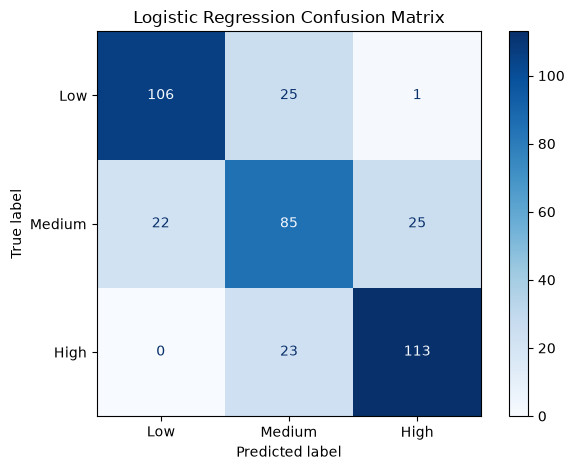

In [15]:
# Visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
# Get the optimized cross-validation score
cv_f1 = lr_grid_search.best_score_

# Compare cross-validation and test F1
print("CROSS-VALIDATION VS TEST PERFORMANCE")

print(f"Cross-validation F1 Macro: {cv_f1:.4f}")
print(f"Test F1 Macro: {test_f1:.4f}")
print(f"Difference: {cv_f1 - test_f1:.4f}")

CROSS-VALIDATION VS TEST PERFORMANCE
Cross-validation F1 Macro: 0.7506
Test F1 Macro: 0.7596
Difference: -0.0090
